# Exclusion limits for dark-matter nucleon scattering without latex rendering

In [1]:
import numpy as np
from scipy.interpolate import interp1d

def smooth_curve(x, y, num_points=500):
    """
    Takes coarse x and y data points and returns a smoothed curve.
    Crucially, it interpolates in log10 space to prevent severe oscillations
    since dark matter mass and cross-section span many orders of magnitude.
    """
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    
    # Remove any NaN values before interpolating
    valid = ~np.isnan(x) & ~np.isnan(y)
    x = x[valid]
    y = y[valid]
    
    # Sort by x just in case the digitized points are out of order
    sort_idx = np.argsort(x)
    x, y = x[sort_idx], y[sort_idx]
    
    # Convert to log space
    log_x = np.log10(x)
    log_y = np.log10(y)
    
    # Create cubic interpolation function
    f_interp = interp1d(log_x, log_y, kind='cubic')
    
    # Generate new dense x values and calculate smoothed y values
    log_x_smooth = np.linspace(log_x.min(), log_x.max(), num_points)
    log_y_smooth = f_interp(log_x_smooth)
    
    # Convert back to linear space
    x_smooth = 10**log_x_smooth
    y_smooth = 10**log_y_smooth
    
    return x_smooth, y_smooth

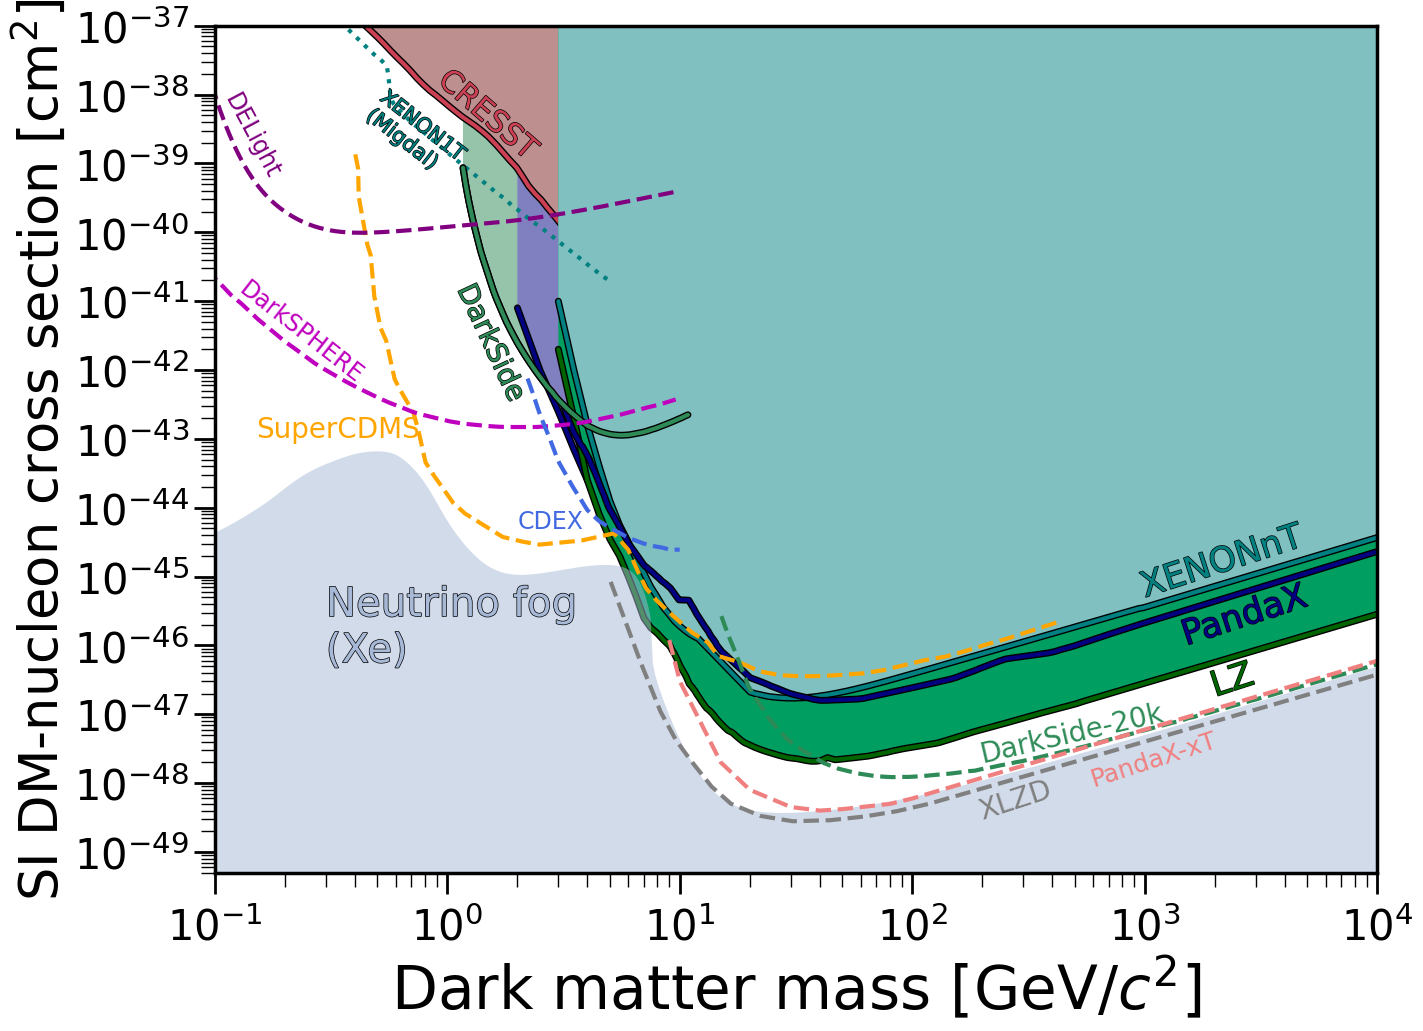

In [4]:
from numpy import *
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from DirectDetectionPlots.notebooks.PlotFuncs import *
import pandas as pd
from pathlib import Path
import os
import sys
cwd = Path.cwd().resolve()
candidates = [
    cwd,
    cwd / "DirectDetectionPlots" / "notebooks",
    cwd / "notebooks",
]

notebook_dir = next(
    (path for path in candidates
     if (path / "sty.mplstyle").is_file()
     and (path / "PlotFuncs.py").is_file()),
    None,
)
if notebook_dir is None:
    raise FileNotFoundError(
        "Could not locate DirectDetectionPlots/notebooks "
        "containing sty.mplstyle and PlotFuncs.py."
    )

os.chdir(notebook_dir)
sys.path.insert(0, str(notebook_dir.parent.parent))
plt.style.use('sty.mplstyle')
# Override the style file's LaTeX requirement
plt.rcParams['text.usetex'] = False
# Tell Matplotlib to just use the default sans-serif font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

fig, ax = plt.subplots()

fpath = '../data/limits/Nucleon/SI/'

rot_45 = 18

# Plot limits

# PlotBound(ax,fpath+'LZ_2024.txt',edgecolor='darkgreen',textcolor='darkgreen',facecolor=[0.0, 0.62, 0.38],label='LZ')
# PlotBound(ax,fpath+'LZ_2026_low_mass.txt',edgecolor='darkgreen',textcolor='darkgreen',facecolor=[0.0, 0.62, 0.38],label='LZ',rotation=rot_45,label_pos=[2000,1.8e-47])
PlotBound(ax,fpath+'LZ_2026_Combined.txt',edgecolor='darkgreen',textcolor='darkgreen',facecolor=[0.0, 0.62, 0.38],label='LZ',rotation=rot_45,label_pos=[2000,1.8e-47])

# PlotBound(ax,fpath+'XENONnT_2026_s2_only.txt',edgecolor='teal',textcolor='teal',facecolor=col_alpha('teal',0.5),zorder=-1)
# PlotBound(ax,fpath+'XENONnT_2026_low_mass.txt',edgecolor='teal',textcolor='teal',facecolor=col_alpha('teal',0.5),zorder=-1)
PlotBound(ax,fpath+'XENONnT_2026_Combined.txt',edgecolor='teal',textcolor='teal',facecolor=col_alpha('teal',0.5),label='XENONnT',rotation=rot_45,label_pos=[1000,5.0e-46])
PlotBound(ax,fpath+'XENON1T-Migdal.txt',edgecolor='teal',textcolor='teal',linestyle=':',facealpha=0,label='XENON1T\n(Migdal)',fontsize=15,rotation=-38,label_pos=[0.45,0.5e-38],path_effects=None)

PlotBound(ax,fpath+'PandaX_2024_Combined.txt',edgecolor='navy',textcolor='navy',facealpha=0,label='PandaX',rotation=rot_45,label_pos=[1500,1.0e-46])
# PlotBound(ax,fpath+'PandaX_2024_Combined.txt',edgecolor='navy',textcolor='navy',facecolor=col_alpha('navy',0.5),zorder=-1.1)
PlotBound(ax,fpath+'PandaX_2025_low_mass.txt',edgecolor='navy',textcolor='navy',facecolor=col_alpha('navy',0.5),zorder=-1.1)

PlotBound(ax,fpath+'CRESST.txt',edgecolor=[0.8, 0.25, 0.33],textcolor=[0.8, 0.25, 0.33],facecolor=[0.74, 0.56, 0.56],zorder=-1,label='CRESST',rotation=-41,label_pos=[0.9,1.5e-38],fontsize=22)

PlotBound(ax,fpath+'DarkSide-50_2022.txt',edgecolor='seagreen',textcolor='seagreen',facecolor='seagreen',facealpha=0.0,label='DarkSide',rotation=-65,label_pos=[1.1,1.5e-41],fontsize=20)
PlotBound(ax,fpath+'DarkSide-50_2022.txt',edgecolor='seagreen',textcolor='seagreen',facecolor='seagreen',facealpha=0.5,zorder=-3)

# PlotBound(ax,fpath+'EDELWEISS.txt',edgecolor='orange',textcolor='orange',facealpha=0,label='EDELWEISS',rotation=-45,label_pos=[8,3e-42],fontsize=17)
# PlotBound(ax,fpath+'DEAP-3600.txt',edgecolor='#4ff09d',textcolor='#4ff09d',facealpha=0,label='DEAP-3600',rotation=rot_45-1,label_pos=[1000,1.9e-44])
# PlotBound(ax,fpath+'PICO60.txt',edgecolor=[0.5, 0.0, 0.13],textcolor=[0.5, 0.0, 0.13],facealpha=0,label='PICO60',rotation=rot_45-8,label_pos=[40,1e-43])
# PlotBound(ax,fpath+'COSINE-100.txt',edgecolor='gold',textcolor='gold',facealpha=0,label='COSINE-100',rotation=rot_45-2,label_pos=[300,7e-42])
# PlotBound(ax,fpath+'NEWS-G.txt',edgecolor='m',textcolor='m',facealpha=0,label='NEWS-G',rotation=6,label_pos=[17,0.35e-38])


# neutrino fog
PlotBound(ax,'../data/fog/Nucleon/SI/nuFog_n2_Xe.txt',y2=0,label='Neutrino fog\n(Xe)',label_pos=[0.3,7e-47],fontsize=29,rotation=0,facecolor='#a7b9d6',lw=0,textcolor='#a7b9d6',facealpha=0.5)


# DAMA
# PlotBound(ax,fpath+'DAMA1.txt',y2=nan,edgecolor='darkslategray',textcolor='darkslategray',facecolor='forestgreen',label='DAMA',label_pos=[22,5e-40])
# PlotBound(ax,fpath+'DAMA2.txt',y2=nan,edgecolor='darkslategray',textcolor='darkslategray',facecolor='forestgreen')
# plt.arrow(0.485, 0.735, -0.012, -0.018, transform=fig.transFigure,figure=fig,length_includes_head=False,lw=1,head_width=0.007, head_length=0.014, overhang=0.13,edgecolor='darkslategray',facecolor='darkslategray',clip_on=True,path_effects=line_background(2,'k'))
# plt.arrow(0.55, 0.73, 0.012, -0.055, transform=fig.transFigure,figure=fig,length_includes_head=False,lw=1,head_width=0.007, head_length=0.014, overhang=0.13,edgecolor='darkslategray',facecolor='darkslategray',clip_on=True,path_effects=line_background(2,'k'))

# Finishing touches
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_xlim([0.1,1e4])
ax.set_ylim([5e-50,1e-37])
# Matplotlib's internal math text renderer can handle basic math tags without usetex=True
ax.set_xlabel('Dark matter mass [GeV/$c^2$]')
ax.set_ylabel(r'SI DM-nucleon cross section [cm$^{2}$]', fontsize=38)
locmaj = matplotlib.ticker.LogLocator(base=10.0, subs=(1.0, ), numticks=50)
locmin = matplotlib.ticker.LogLocator(base=10.0, subs=arange(2, 10)*.1,numticks=100)
ax.yaxis.set_major_locator(locmaj)
ax.yaxis.set_minor_locator(locmin)

MySaveFig(fig,'Nucleon_SI')

# Projections
PlotBound(ax,fpath+'Projections/SuperCDMS.txt',edgecolor='orange',textcolor='orange',facealpha=0,label='SuperCDMS',linestyle='--',rotation=0,fontsize=20,label_pos=[0.15,1.05e-43],end_x=-10,path_effects=None,text_path_effects=None)
PlotBound(ax,fpath+'Projections/DarkSide-20k.txt',edgecolor='seagreen',textcolor='seagreen',facealpha=0,label='DarkSide-20k',linestyle='--',rotation=rot_45-5,fontsize=20,label_pos=[200,2.0e-48],path_effects=None,text_path_effects=None)
PlotBound(ax,fpath+'Projections/PandaX-xT-Projection-200-tonne-year.txt',edgecolor='lightcoral',textcolor='lightcoral',facealpha=0,label='PandaX-xT',linestyle='--',rotation=rot_45,fontsize=18,label_pos=[600,0.9e-48],path_effects=None,text_path_effects=None)
PlotBound(ax,fpath+'Projections/LXe_200ty_90excl.txt',edgecolor='gray',textcolor='gray',facealpha=0,label='XLZD',linestyle='--',rotation=rot_45,fontsize=20,label_pos=[200,0.3e-48],path_effects=None,text_path_effects=None)
# PlotBound(ax,fpath+'Projections/NEWS-G-Projection.txt',edgecolor='m',textcolor='m',facealpha=0,label='NEWS-G',linestyle='--',rotation=-60,fontsize=20,label_pos=[0.168,5e-39],path_effects=None,text_path_effects=None)
# PlotBound(ax,fpath+'Projections/SBC.txt',edgecolor=[0.5, 0.0, 0.13],textcolor=[0.5, 0.0, 0.13],facealpha=0,label='SBC',linestyle='--',rotation=-17,fontsize=20,label_pos=[1.8,4e-44],path_effects=None,text_path_effects=None,end_x=-60)
PlotBound(ax,fpath+'Projections/DarkSPHERE.txt',edgecolor='m',textcolor='m',facealpha=0,label='DarkSPHERE',linestyle='--',rotation=-38,fontsize=17,label_pos=[0.125,1.4e-41],path_effects=None,text_path_effects=None)
PlotBound(ax,fpath+'Projections/CDEX.txt',edgecolor='royalblue',textcolor='royalblue',facealpha=0,label='CDEX',linestyle='--',rotation=0,fontsize=17,label_pos=[2,5e-45],path_effects=None,text_path_effects=None)

df_DELight_2026 = pd.read_csv(fpath+'Projections/DELight_2026.txt', sep='\t', comment='#',
                              header=None, names=['mass', 'limit_solid', 'limit_dashed'])

DELight_2026_x, DELight_2026_y = smooth_curve(df_DELight_2026['mass'].values, df_DELight_2026['limit_solid'].values)

PlotBound(ax,filename=None, mass_data=DELight_2026_x, limit_data=DELight_2026_y,edgecolor='purple',textcolor='purple',facealpha=0,label='DELight',linestyle='--',rotation=-62,fontsize=17,label_pos=[0.11, 9e-39],path_effects=None,text_path_effects=None)

MySaveFig(fig,'Nucleon_SI_with_Projections_no_latex')

## WIMP-LEGEND integration: calculated limits, not handwritten projections

This adapter reads **actual SI results** (`limits.csv` + `manifest.json`) from a completed `poster-workbench` run. It replaces the hard-coded LEGEND arrays in the following two panels. The original experiment/projection plotting functions and style are preserved.

**Run directory:** set `WIMP_LEGEND_REPO` in your environment or edit `LEGEND_REPO` below. By default, the newest complete run is used, with a fallback to the published validation snapshot. If you have multiple threshold runs, add their folders to `EXTRA_RUN_DIRS`.

**Important:** the current standard result has a **100 eVee threshold** and exposures **1, 10, 100 kg·yr**, i.e. only **0.1 t·yr** from the second figure. No 150-eV, 1-t·yr or 10-t·yr curves will be fabricated. Missing combinations are explicitly listed. At present the mass grid contains only seven calculated points; the adapter **does not spline-smooth** these points.

The full plotting notebook still requires the upstream `PlotFuncs.py`, `sty.mplstyle`, and experiment/fog data files beside it in the usual DirectDetectionPlots directory layout. The uploaded notebook alone does not include those dependencies.

In [5]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import pandas as pd

# Set this to your local WIMP-LEGEND checkout if WIMP_LEGEND_REPO is not set.
# The default is taken from the path printed by your executed workbench notebook.
LEGEND_REPO = Path(os.environ.get(
    'WIMP_LEGEND_REPO',
    r'C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code'
))
EXTRA_RUN_DIRS = []  # Optional additional completed runs for other thresholds / exposures
SCENARIO = 'legend_poster'
METHOD = 'poisson_cls_counting'


def _read_verified_run(folder):
    folder = Path(folder)
    manifest_path, csv_path = folder/'manifest.json', folder/'limits.csv'
    if not manifest_path.is_file() or not csv_path.is_file():
        raise FileNotFoundError(f'Missing manifest.json or limits.csv in {folder}')
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    sha = manifest.get('output_sha256', {}).get('limits.csv')
    if sha and hashlib.sha256(csv_path.read_bytes()).hexdigest() != sha:
        raise ValueError(f'Limits CSV checksum mismatch in {folder}')
    df = pd.read_csv(csv_path)
    required = {'scenario','background','mass_GeV','operator','exposure_kg_day',
                'method','limit_value','confidence_level','reference_signal_events'}
    missing = required-set(df.columns)
    if missing:
        raise ValueError(f'Incomplete limits.csv ({folder}): {sorted(missing)}')
    cfg = manifest['resolved_configuration']
    df = df.copy()
    df['threshold_keVee'] = df['scenario'].map({
        name: cfg['detector']['presets'][record.get('detector',cfg['detector']['default'])]['threshold_keV_obs']
        for name,record in cfg['background']['scenarios'].items()
    })
    df['exposure_tyr'] = df['exposure_kg_day'] / (1000.0*cfg['analysis']['days_per_year'])
    df['run_dir'] = str(folder)
    df['source_commit'] = manifest.get('source', {}).get('git_commit','unknown')
    df['si_sigma_ref_cm2'] = cfg['signal']['sigma_p_ref_cm2']
    df['source_status'] = cfg['status']
    # Retain only physical, finite successful results, not NREFT coefficients.
    df = df[(df['operator']==1) & np.isfinite(df['limit_value']) & (df['limit_value']>0)]
    if 'status' in df.columns:
        df = df[df['status']=='success']
    return df


def _auto_run_dir(repo):
    root = repo/'analyses'/'legend_poster'
    runs = sorted((root/'runs').glob('*/manifest.json'),
                  key=lambda p:p.stat().st_mtime,reverse=True)
    for manifest in runs:
        if (manifest.parent/'limits.csv').is_file():
            return manifest.parent
    fallback = root/'validation'/'standard'
    if (fallback/'limits.csv').is_file():
        return fallback
    raise FileNotFoundError(
        'No completed WIMP-LEGEND run found. Set LEGEND_REPO to your checkout, '
        'or list run folders in EXTRA_RUN_DIRS.')

RUN_DIRS = [_auto_run_dir(LEGEND_REPO)] + [Path(p) for p in EXTRA_RUN_DIRS]
legend_limits = pd.concat([_read_verified_run(p) for p in RUN_DIRS], ignore_index=True)
print('Loaded:', *RUN_DIRS, sep='\n  ')
print('Available SI combinations (tonne-years, electron-equivalent threshold):')
print(legend_limits[['scenario','background','threshold_keVee','exposure_tyr','source_commit']]
      .drop_duplicates().to_string(index=False))


def legend_series(*, scenario=SCENARIO, background='revised',
                  threshold_keVee=0.1, exposure_tyr=0.1, method=METHOD):
    df = legend_limits[
        (legend_limits.scenario == scenario) &
        (legend_limits.background == background) &
        (legend_limits.method == method) &
        np.isclose(legend_limits.threshold_keVee, threshold_keVee, atol=1e-10, rtol=0) &
        np.isclose(legend_limits.exposure_tyr, exposure_tyr, atol=1e-10, rtol=0)
    ].sort_values('mass_GeV')
    if df.empty:
        return None
    if df.mass_GeV.duplicated().any():
        raise ValueError('Multiple runs supply identical mass points. Select only one matching run.')
    return df


def plot_legend_series(ax, *, label, color, background='revised',
                       threshold_keVee=0.1, exposure_tyr=0.1,
                       scenario=SCENARIO, linestyle='-', **kwargs):
    points = legend_series(scenario=scenario, background=background,
                           threshold_keVee=threshold_keVee, exposure_tyr=exposure_tyr)
    if points is None:
        print(f'NOT CALCULATED: {label} (threshold={threshold_keVee} keVee, '
              f'exposure={exposure_tyr} t·yr, scenario={scenario}, background={background})')
        return None
    line, = ax.plot(points.mass_GeV, points.limit_value, color=color,
                    linestyle=linestyle, linewidth=2.5, marker='o', markersize=4,
                    label=label, zorder=6, **kwargs)
    return line


Loaded:
  C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\runs\db98e4db2092c27c8a25
Available SI combinations (tonne-years, electron-equivalent threshold):
     scenario background  threshold_keVee  exposure_tyr                            source_commit
  natural_AAr    revised              0.1         0.001 105e19cdd591546f47a155c620ede1ef13280e29
  natural_AAr    revised              0.1         0.010 105e19cdd591546f47a155c620ede1ef13280e29
  natural_AAr    revised              0.1         0.100 105e19cdd591546f47a155c620ede1ef13280e29
 enriched_UAr    revised              0.1         0.001 105e19cdd591546f47a155c620ede1ef13280e29
 enriched_UAr historical              0.1         0.001 105e19cdd591546f47a155c620ede1ef13280e29
 enriched_UAr    revised              0.1         0.010 105e19cdd591546f47a155c620ede1ef13280e29
 enriched_UAr historical              0.1         0.010 105e19cdd591546f47a155c620ede1ef13280e29
 enriched_UAr    r

NOT CALCULATED: LEGEND full benchmark, 150 eVee (threshold=0.15 keVee, exposure=0.1 t·yr, scenario=legend_poster, background=revised)


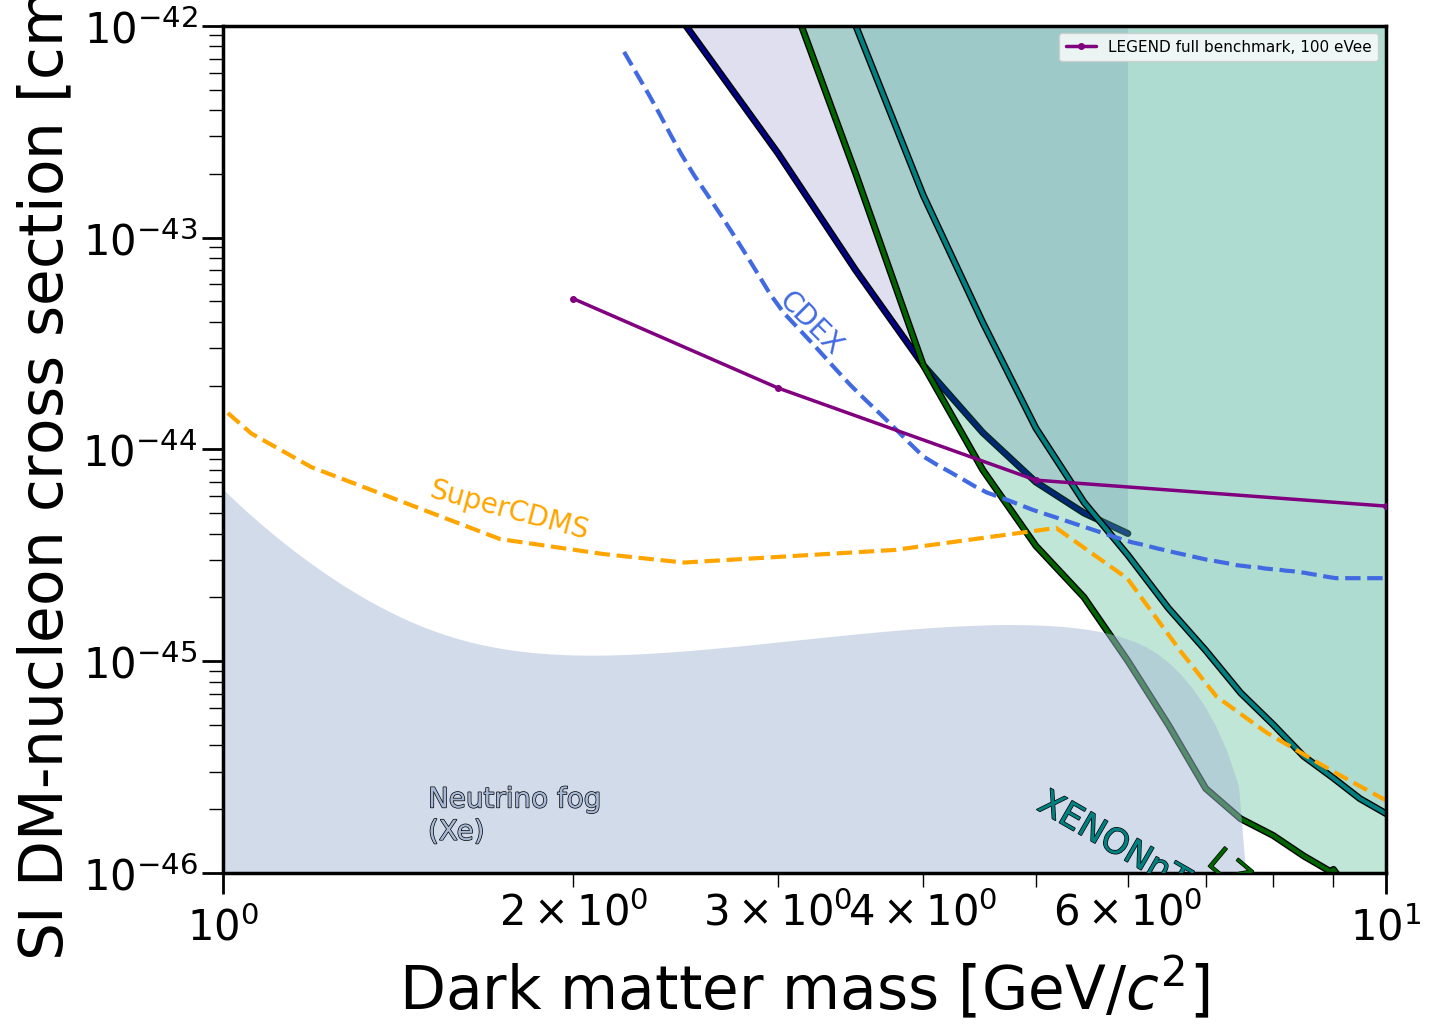

In [6]:
# LEGEND: threshold/background comparison from genuine WIMP-LEGEND run output
from numpy import *
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from PlotFuncs import *

plt.style.use('sty.mplstyle')
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

fig, ax = plt.subplots()
fpath = '../data/limits/Nucleon/SI/'
PlotBound(ax,fpath+'LZ_2026_Combined.txt',edgecolor='darkgreen',textcolor='darkgreen',facecolor=[0.0, 0.62, 0.38],facealpha=0.25,label='LZ',rotation=-40,label_pos=[7, 1.1e-46])
PlotBound(ax,fpath+'XENONnT_2026_Combined.txt',edgecolor='teal',textcolor='teal',facecolor=col_alpha('teal',0.5),facealpha=0.25,label='XENONnT',rotation=-30,label_pos=[5, 2e-46])
PlotBound(ax,fpath+'PandaX_2025_low_mass.txt',edgecolor='navy',textcolor='navy',facecolor=col_alpha('navy',0.5),facealpha=0.25,zorder=-1.1)
PlotBound(ax,'../data/fog/Nucleon/SI/nuFog_n2_Xe.txt',y2=0,label='Neutrino fog\n(Xe)',label_pos=[1.5,1.5e-46],fontsize=20,rotation=0,facecolor='#a7b9d6',lw=0,textcolor='#a7b9d6',facealpha=0.5)
PlotBound(ax,fpath+'Projections/SuperCDMS.txt',edgecolor='orange',textcolor='orange',facealpha=0,label='SuperCDMS',linestyle='--',rotation=-15,fontsize=20,label_pos=[1.5,6e-45],end_x=-10,path_effects=None,text_path_effects=None)
PlotBound(ax,fpath+'Projections/CDEX.txt',edgecolor='royalblue',textcolor='royalblue',facealpha=0,label='CDEX',linestyle='--',rotation=-45,fontsize=20,label_pos=[3,5e-44],path_effects=None,text_path_effects=None)

# Only available REAL curves are plotted; missing scenarios produce a diagnostic.
plot_legend_series(ax,label='LEGEND full benchmark, 100 eVee',color='purple',threshold_keVee=0.1,exposure_tyr=0.1)
plot_legend_series(ax,label='LEGEND full benchmark, 150 eVee',color='navy',threshold_keVee=0.15,exposure_tyr=0.1)
# For a dedicated no-background or neutrino-only computed run, add its scenario name here.

ax.set(xscale='log',yscale='log',xlim=(1,10),ylim=(1e-46,1e-42),
       xlabel='Dark matter mass [GeV/$c^2$]',
       ylabel=r'SI DM-nucleon cross section [cm$^2$]')
ax.legend(loc='upper right',fontsize=11,frameon=True)
MySaveFig(fig,'LEGEND_real_threshold_comparison')


NOT CALCULATED: 1 tonne-year (threshold=0.1 keVee, exposure=1.0 t·yr, scenario=legend_poster, background=revised)
NOT CALCULATED: 10 tonne-year (threshold=0.1 keVee, exposure=10.0 t·yr, scenario=legend_poster, background=revised)


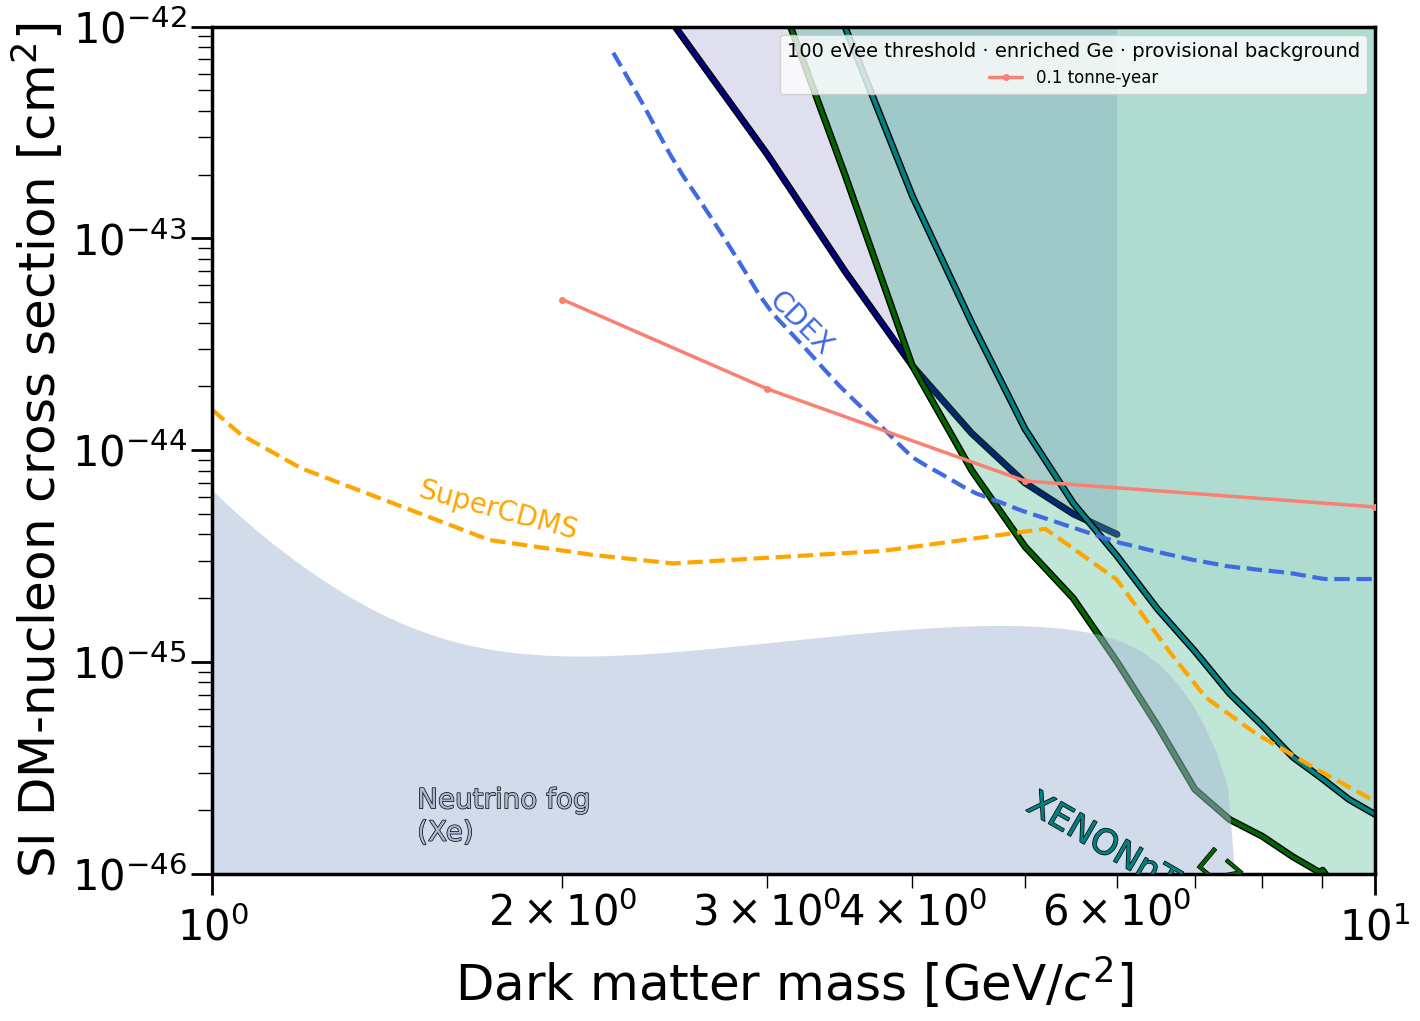

In [26]:
# LEGEND: exposure comparison from genuine WIMP-LEGEND run output
from numpy import *
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from PlotFuncs import *

plt.style.use('sty.mplstyle')
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
# plt.rcParams['font.size'] = 10

fig, ax = plt.subplots()
fpath = '../data/limits/Nucleon/SI/'
PlotBound(ax,fpath+'LZ_2026_Combined.txt',edgecolor='darkgreen',textcolor='darkgreen',facecolor=[0.0, 0.62, 0.38],facealpha=0.25,label='LZ',rotation=-40,label_pos=[7, 1.1e-46])
PlotBound(ax,fpath+'XENONnT_2026_Combined.txt',edgecolor='teal',textcolor='teal',facecolor=col_alpha('teal',0.5),facealpha=0.25,label='XENONnT',rotation=-30,label_pos=[5, 2e-46])
PlotBound(ax,fpath+'PandaX_2025_low_mass.txt',edgecolor='navy',textcolor='navy',facecolor=col_alpha('navy',0.5),facealpha=0.25,zorder=-1.1)
PlotBound(ax,'../data/fog/Nucleon/SI/nuFog_n2_Xe.txt',y2=0,label='Neutrino fog\n(Xe)',label_pos=[1.5,1.5e-46],fontsize=20,rotation=0,facecolor='#a7b9d6',lw=0,textcolor='#a7b9d6',facealpha=0.5)
PlotBound(ax,fpath+'Projections/SuperCDMS.txt',edgecolor='orange',textcolor='orange',facealpha=0,label='SuperCDMS',linestyle='--',rotation=-15,fontsize=20,label_pos=[1.5,6e-45],end_x=-10,path_effects=None,text_path_effects=None)
PlotBound(ax,fpath+'Projections/CDEX.txt',edgecolor='royalblue',textcolor='royalblue',facealpha=0,label='CDEX',linestyle='--',rotation=-45,fontsize=20,label_pos=[3,5e-44],path_effects=None,text_path_effects=None)

# Note: 0.1, 1 and 10 t·yr are requested by the previous notebook, but a
# curve appears ONLY if an actual calculation with that exposure exists.
plot_legend_series(ax,label='0.1 tonne-year',color='salmon',threshold_keVee=0.1,exposure_tyr=0.1)
plot_legend_series(ax,label='1 tonne-year',color='red',threshold_keVee=0.1,exposure_tyr=1.0)
plot_legend_series(ax,label='10 tonne-year',color='darkred',threshold_keVee=0.1,exposure_tyr=10.0)

ax.set(xscale='log',yscale='log',xlim=(1,10),ylim=(1e-46,1e-42),
       xlabel='Dark matter mass [GeV/$c^2$]',
       ylabel=r'SI DM-nucleon cross section [cm$^2$]')
ax.xaxis.label.set_size(36)
ax.yaxis.label.set_size(36)
# ax.tick_params(axis='both', which='major', labelsize=10)
ax.legend(title='100 eVee threshold · enriched Ge · provisional background',
          title_fontsize=14,loc='upper right',fontsize=12,frameon=True)
MySaveFig(fig,'LEGEND_real_exposure_comparison')
